# Fleet Infringement Cost Leakage & Recovery Triage

**Where a rental fleet loses money on traffic fines and tolls, why, and which notices to work first.**

Python · pandas · matplotlib · scikit-learn

---

## About the data

Every row in this project is **synthetic**, generated in Part 1 below.

I process fines, tolls and infringement notices for a fleet of 120+ Australian
vehicles as part of my day job, including direct liaison with Revenue NSW. That data
is confidential and does not appear here. Instead I rebuilt the workflow from the real
rules — the statutory nomination window, the liability transfer, the toll rebill
mechanics — and then analysed the result as if it were a register I had been handed.

The domain knowledge is real. The data is not. Both of those statements matter.

---

## How liability actually works

This is the part most analyses of this problem get wrong, so it is worth being
precise. **Fines and tolls behave in opposite ways.**

### Infringements (speed, red light, parking, bus lane, mobile phone)

The notice arrives in the company's name, because the company is the registered
owner. The company then has 21 days — the Revenue NSW driver nomination window — to
name the hirer who was driving.

If the nomination is submitted in time, **liability transfers to the hirer
completely.** The penalty moves off the company's books. It does not matter whether
that person has since flown home, ignores their email, or left no card on file — that
is now between them and Revenue NSW. The company's exposure is zero.

If the window is missed, **the company pays the fine itself, permanently, with no
appeal.**

### Tolls

Tolls work the other way. There is no nomination process. The toll operator bills the
registered owner, so **the company pays the toll first and rebills the hirer
afterwards**, against the card on file plus a small fee.

Here the money genuinely has to be collected. A hirer who has gone overseas with no
card on file is a real, permanent loss.

### So the company absorbs cost in exactly three ways

1. **A nomination deadline is missed** → the full penalty. Big amounts, low volume.
2. **No hire can be matched to the notice** → nobody to nominate or bill.
3. **A billable amount is never collected** → toll rebills and fees. Small amounts, high volume.

Nobody is measuring any of this. That is what this project quantifies.

---

---

## How the notebook is organised

| Part | Stage | What happens |
|---|---|---|
| 1 | **Data generation** | Build the dataset from the real business rules |
| 2 | **Exploratory data analysis (EDA)** | Look at the raw register and find what is wrong with it |
| 3 | **Data cleaning and preparation** | Fix what EDA found, match notices to hires, build the cost columns |
| 4 | **Descriptive analytics** | What happened, how much it cost, and who owns each cause |
| 5 | **Predictive analytics** | Score which bills will never be collected, and check the score is worth having |

EDA comes **before** cleaning on purpose. You cannot sensibly clean a dataset you have
not looked at — the exploration is what tells you which problems exist and how big they
are, and Part 3 then fixes exactly those.

---

## How to run this

Runtime → Run all. About a minute. Colab already has everything installed.

The random seed is fixed, so the numbers come out the same every time. Run the cells
**in order** — each one uses the tables built above it.

---
# Setup

Load the libraries and write down the business rules. Nothing is calculated here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

# Fix the random seed so the generated data is identical every run.
np.random.seed(42)

# ---- The business rules ----
NOMINATION_WINDOW_DAYS = 21   # days to nominate the driver and transfer liability
FEE_INFRINGEMENT = 33.00      # what we can charge the hirer per nomination processed
FEE_TOLL = 5.50               # what we can charge per toll rebilled

PERIOD_START = datetime(2024, 1, 1)
PERIOD_END = datetime(2025, 12, 31)

N_VEHICLES = 132
N_HIRERS = 3200

BRANCHES = ["Sydney Airport", "Parramatta", "Newcastle"]

plt.rcParams["figure.figsize"] = (9, 4.5)

print("Setup done.")

Setup done.


---
# Part 1 — Data generation

The next six cells invent the dataset: vehicles, hirers, hires, notices, and what
happened to each notice. They produce four tables that the rest of the project treats
as if someone had handed them over.

### 1.1 Vehicles

132 vehicles. About 8% are sold part-way through the period — those are the ones most
likely to produce a notice we cannot match to anybody later.

In [2]:
makes = ["Toyota Corolla", "Toyota RAV4", "Hyundai i30", "Mazda CX-5", "Kia Cerato",
         "Toyota HiAce", "Ford Ranger", "Mitsubishi Outlander", "Nissan X-Trail",
         "Toyota Camry"]
body_types = ["Hatch", "SUV", "Hatch", "SUV", "Sedan", "Van", "Ute", "SUV", "SUV", "Sedan"]

# Letters used on number plates. I and O are left out because they look like 1 and 0.
LETTERS = list("ABCDEFGHJKLMNPQRSTUVWXY")
DIGITS = list("0123456789")

vehicle_rows = []
used_plates = []

for i in range(N_VEHICLES):

    # Build a plate like ABC-12D, and keep trying until we get one we haven't used.
    plate = ""
    while plate == "" or plate in used_plates:
        plate = ("".join(np.random.choice(LETTERS, 3)) + "-"
                 + "".join(np.random.choice(DIGITS, 2))
                 + np.random.choice(LETTERS))
    used_plates.append(plate)

    model_index = np.random.randint(0, len(makes))

    # 8% of vehicles get sold somewhere in the middle of the period.
    if np.random.random() < 0.08:
        disposed = PERIOD_START + timedelta(days=np.random.randint(200, 700))
    else:
        disposed = None

    vehicle_rows.append({
        "vehicle_id": "VEH" + str(i + 1).zfill(4),
        "registration": plate,
        "model": makes[model_index],
        "body_type": body_types[model_index],
        "home_branch": np.random.choice(BRANCHES, p=[0.55, 0.30, 0.15]),
        "disposed_date": disposed,
    })

vehicles = pd.DataFrame(vehicle_rows)

print(len(vehicles), "vehicles")
print(vehicles["disposed_date"].notna().sum(), "sold during the period")
vehicles.head()

132 vehicles
5 sold during the period


,vehicle_id,registration,model,body_type,home_branch,disposed_date
0,VEH0001,GVQ-74G,Toyota Camry,Sedan,Sydney Airport,NaT
1,VEH0002,WDH-72X,Kia Cerato,Sedan,Parramatta,NaT
2,VEH0003,FBW-09X,Nissan X-Trail,SUV,Parramatta,NaT
3,VEH0004,KRQ-26V,Nissan X-Trail,SUV,Parramatta,2025-05-21
4,VEH0005,JGT-38P,Toyota RAV4,SUV,Sydney Airport,NaT


### 1.2 Hirers

The important column here is `card_on_file`.

Note carefully what it does and does not affect. It has **no bearing on whether a fine
can be transferred** — a nomination is a legal notification, not a payment. It matters
entirely for collecting toll rebills and processing fees.

Corporate accounts have good records. Overseas tourists have the worst.

In [3]:
hirer_rows = []

for i in range(N_HIRERS):

    is_corporate = np.random.random() < 0.22

    # Overseas hirers are tourists. Much harder to bill once they fly home.
    if not is_corporate and np.random.random() < 0.18:
        country = np.random.choice(["New Zealand", "United Kingdom", "United States",
                                    "China", "India"])
    else:
        country = "Australia"

    if is_corporate:
        has_email = np.random.random() < 0.97
        has_phone = np.random.random() < 0.95
        has_card = np.random.random() < 0.93
    else:
        has_email = np.random.random() < 0.82
        has_phone = np.random.random() < 0.88
        if country == "Australia":
            has_card = np.random.random() < 0.71
        else:
            has_card = np.random.random() < 0.52

    hirer_rows.append({
        "hirer_id": "HIR" + str(i + 1).zfill(5),
        "hirer_type": "Corporate" if is_corporate else "Individual",
        "country": country,
        "email_on_file": int(has_email),
        "phone_on_file": int(has_phone),
        "card_on_file": int(has_card),
    })

hirers = pd.DataFrame(hirer_rows)

print(len(hirers), "hirers")
print(hirers["hirer_type"].value_counts())
print()
print("No card on file:", round(100 * (1 - hirers["card_on_file"].mean()), 1), "%")
hirers.head()

3200 hirers
hirer_type
Individual    2468
Corporate      732
Name: count, dtype: int64

No card on file: 27.9 %


,hirer_id,hirer_type,country,email_on_file,phone_on_file,card_on_file
0,HIR00001,Individual,Australia,1,1,0
1,HIR00002,Corporate,Australia,1,1,1
2,HIR00003,Individual,Australia,1,1,1
3,HIR00004,Individual,Australia,0,1,1
4,HIR00005,Corporate,Australia,1,1,1


### 1.3 Rental agreements

Each vehicle gets a run of hires, one after another, with gaps in between. The gaps
are genuine idle time at the depot — a notice landing in a gap is the "no hire found"
case the company has to absorb.

The `while` loop keeps hiring each vehicle out until its timeline reaches the end of
the period. An earlier version used a fixed number of hires per vehicle, which only
covered the first year and left 2025 empty — that quietly broke the model later, so
the loop runs on time rather than on a count.

In [4]:
agreement_rows = []
agreement_number = 1

for i in range(len(vehicles)):

    vehicle = vehicles.iloc[i]

    # When does this vehicle leave the fleet?
    if pd.isna(vehicle["disposed_date"]):
        vehicle_end = PERIOD_END
    else:
        vehicle_end = vehicle["disposed_date"]

    cursor = PERIOD_START + timedelta(days=np.random.randint(0, 10))

    while cursor < vehicle_end:

        # Most hires are short, a few are long corporate leases.
        hire_days = int(np.random.gamma(1.9, 3.4))
        if hire_days < 1:
            hire_days = 1
        if hire_days > 60:
            hire_days = 60

        start = cursor + timedelta(days=np.random.randint(0, 6),
                                   hours=np.random.randint(7, 19))
        end = start + timedelta(days=hire_days, hours=np.random.randint(0, 6))

        if end > vehicle_end:
            break

        hirer = hirers.iloc[np.random.randint(0, len(hirers))]

        agreement_rows.append({
            "agreement_id": "AGR" + str(agreement_number).zfill(6),
            "registration": vehicle["registration"],
            "hirer_id": hirer["hirer_id"],
            "pickup_branch": vehicle["home_branch"],
            "start_datetime": start,
            "end_datetime": end,
            "hire_days": hire_days,
        })

        agreement_number = agreement_number + 1
        cursor = end + timedelta(days=np.random.randint(0, 5))

agreements = pd.DataFrame(agreement_rows)

print(len(agreements), "rental agreements")
print("Average hire length:", round(agreements["hire_days"].mean(), 1), "days")
print()
print("Hires starting each year (both years must have data):")
print(agreements["start_datetime"].dt.year.value_counts().sort_index())
agreements.head()

8399 rental agreements
Average hire length: 6.0 days

Hires starting each year (both years must have data):
start_datetime
2024    4291
2025    4108
Name: count, dtype: int64


,agreement_id,registration,hirer_id,pickup_branch,start_datetime,end_datetime,hire_days
0,AGR000001,GVQ-74G,HIR00942,Sydney Airport,2024-01-10 15:00:00,2024-01-13 15:00:00,3
1,AGR000002,GVQ-74G,HIR01250,Sydney Airport,2024-01-17 02:00:00,2024-01-20 07:00:00,3
2,AGR000003,GVQ-74G,HIR01725,Sydney Airport,2024-01-27 00:00:00,2024-01-28 03:00:00,1
3,AGR000004,GVQ-74G,HIR01261,Sydney Airport,2024-02-03 17:00:00,2024-02-05 19:00:00,2
4,AGR000005,GVQ-74G,HIR01399,Sydney Airport,2024-02-12 11:00:00,2024-03-01 11:00:00,18


### 1.4 The notices

Six types of notice, with real NSW penalty amounts. The `needs_nomination` column is
the one that matters — it separates the two liability regimes:

- **True** → a fine. Liability can be transferred within 21 days.
- **False** → a toll. No transfer exists; the company pays and rebills.

Two groups get built. About 94% happen during a real hire. The remaining 6% are placed
in the gaps between hires, so the matching step in Part 3 genuinely cannot resolve
them.

In [5]:
# type, share of volume, needs nomination, authority, days to arrive (low, high)
notice_types = [
    ["Toll",         0.58, False, "Linkt",          6,  21],
    ["Speed Camera", 0.14, True,  "Revenue NSW",    12, 34],
    ["Parking",      0.13, True,  "Local Council",  8,  26],
    ["Bus Lane",     0.06, True,  "Revenue NSW",    14, 32],
    ["Red Light",    0.05, True,  "Revenue NSW",    14, 35],
    ["Mobile Phone", 0.04, True,  "Revenue NSW",    15, 38],
]

type_names = [row[0] for row in notice_types]
type_weights = [row[1] for row in notice_types]


def penalty_for(notice_type):
    """Pick a realistic penalty amount for this type of notice."""
    if notice_type == "Toll":
        return round(np.random.uniform(2.80, 19.50), 2)
    if notice_type == "Speed Camera":
        return float(np.random.choice([137, 293, 494, 941, 2482],
                                      p=[0.50, 0.26, 0.14, 0.07, 0.03]))
    if notice_type == "Parking":
        return float(np.random.choice([120, 198, 320, 387],
                                      p=[0.42, 0.31, 0.18, 0.09]))
    if notice_type == "Bus Lane":
        return 387.00
    if notice_type == "Red Light":
        return 544.00
    return 410.00   # Mobile Phone


notice_rows = []
notice_number = 1

# ---- Group 1: notices that happened during a real hire ----
for i in range(7400):

    agreement = agreements.iloc[np.random.randint(0, len(agreements))]
    type_index = np.random.choice(len(notice_types), p=type_weights)
    name, share, needs_nom, authority, lag_low, lag_high = notice_types[type_index]

    # Pick a random moment inside the hire.
    hire_seconds = (agreement["end_datetime"] - agreement["start_datetime"]).total_seconds()
    offence = agreement["start_datetime"] + timedelta(seconds=np.random.uniform(0, hire_seconds))

    if offence > PERIOD_END:
        continue

    notice_rows.append({
        "notice_id": "INF" + str(notice_number).zfill(6),
        "registration": agreement["registration"],
        "notice_type": name,
        "needs_nomination": needs_nom,
        "authority": authority,
        "offence_datetime": offence,
        "notice_received_date": offence + timedelta(days=np.random.randint(lag_low, lag_high)),
        "penalty_amount": penalty_for(name),
    })
    notice_number = notice_number + 1

# ---- Group 2: notices with no matching hire ----
# Pick a random vehicle and a random moment, and keep it only if the vehicle was
# NOT on hire at that moment. That guarantees Part 3 cannot match them.
period_seconds = (PERIOD_END - PERIOD_START).total_seconds()
unmatched_made = 0
attempts = 0

while unmatched_made < 420 and attempts < 30000:

    attempts = attempts + 1

    plate = vehicles["registration"].iloc[np.random.randint(0, len(vehicles))]
    moment = PERIOD_START + timedelta(seconds=np.random.uniform(0, period_seconds))

    this_vehicle = agreements[agreements["registration"] == plate]
    on_hire = ((this_vehicle["start_datetime"] <= moment)
               & (this_vehicle["end_datetime"] >= moment)).any()

    if on_hire:
        continue

    type_index = np.random.choice(len(notice_types), p=type_weights)
    name, share, needs_nom, authority, lag_low, lag_high = notice_types[type_index]

    notice_rows.append({
        "notice_id": "INF" + str(notice_number).zfill(6),
        "registration": plate,
        "notice_type": name,
        "needs_nomination": needs_nom,
        "authority": authority,
        "offence_datetime": moment,
        "notice_received_date": moment + timedelta(days=np.random.randint(lag_low, lag_high)),
        "penalty_amount": penalty_for(name),
    })
    notice_number = notice_number + 1
    unmatched_made = unmatched_made + 1

notices = pd.DataFrame(notice_rows)

print(len(notices), "notices")
print(unmatched_made, "of them have no matching hire")
print()
print(notices["notice_type"].value_counts())
notices.head()

7820 notices
420 of them have no matching hire

notice_type
Toll            4573
Speed Camera    1081
Parking         1044
Bus Lane         458
Red Light        380
Mobile Phone     284
Name: count, dtype: int64


,notice_id,registration,notice_type,needs_nomination,authority,offence_datetime,notice_received_date,penalty_amount
0,INF000001,ECY-18K,Toll,False,Linkt,2025-02-25 03:07:33.666788,2025-03-08 03:07:33.666788,10.16
1,INF000002,RTG-96A,Toll,False,Linkt,2025-04-08 17:41:12.202662,2025-04-22 17:41:12.202662,5.11
2,INF000003,ESR-64W,Toll,False,Linkt,2025-05-28 15:24:53.700154,2025-06-15 15:24:53.700154,19.10
3,INF000004,SSS-11X,Toll,False,Linkt,2025-03-21 14:13:32.640457,2025-03-30 14:13:32.640457,2.93
4,INF000005,ARY-67E,Toll,False,Linkt,2024-07-22 04:27:47.381649,2024-07-31 04:27:47.381649,9.17


### 1.5 What happened to each notice

This cell is the heart of the project. For every notice it works out what the company
ended up paying.

Two things drive the outcome, and they are worth reading slowly:

**The processing lag** — how long the back office takes to act. Normally about 7 days.
But two backlog periods are built in: mid-December to late January (peak hire volume
plus annual leave), and June to August 2025 (a team member left and was not replaced).
In those periods the lag rises to around 20 days, against a 21-day deadline.

**The billing failure chance** — the odds a billable amount is never collected. This
applies **only** to toll rebills and processing fees. It does not apply to a
transferred penalty, because a transferred penalty is not the company's money to
collect.

Then four possible outcomes, in order:

1. No matching hire → the company pays the full amount.
2. Fine, nominated in time → **liability transfers, penalty cost is zero.** A $33 fee becomes billable.
3. Fine, nominated late → transfer fails, the company pays the full penalty.
4. Toll → no transfer exists. The company pays, then rebills the toll plus $5.50.

In [6]:
# Make the hires easy to look up by registration.
agreements_sorted = agreements.sort_values("start_datetime")

outcome_rows = []

for i in range(len(notices)):

    notice = notices.iloc[i]
    received = notice["notice_received_date"]

    # ---- How long does the back office take? ----
    is_holiday_backlog = ((received.month == 12 and received.day >= 14)
                          or (received.month == 1 and received.day <= 22))
    is_staffing_gap = (received.year == 2025 and received.month in [6, 7, 8])

    if is_holiday_backlog:
        lag = np.random.normal(23, 7)
    elif is_staffing_gap:
        lag = np.random.normal(20, 6)
    else:
        lag = np.random.normal(7.5, 4)

    lag = int(lag)
    if lag < 1:
        lag = 1
    if lag > 60:
        lag = 60

    action_date = received + timedelta(days=lag)

    # ---- Which hire was this? ----
    candidates = agreements_sorted[
        (agreements_sorted["registration"] == notice["registration"])
        & (agreements_sorted["start_datetime"] <= notice["offence_datetime"])
        & (agreements_sorted["end_datetime"] >= notice["offence_datetime"])
    ]

    # ---- Outcome 1: nobody to nominate or bill ----
    if len(candidates) == 0:
        outcome_rows.append({
            "processing_days": lag,
            "status": "No hire found - company pays",
            "penalty_absorbed": notice["penalty_amount"],
            "billable_amount": 0.0,
            "billed_recovered": 0.0,
        })
        continue

    agreement = candidates.iloc[0]
    hirer = hirers[hirers["hirer_id"] == agreement["hirer_id"]].iloc[0]

    # ---- Outcome 2: a fine where we missed the deadline ----
    if notice["needs_nomination"] and lag > NOMINATION_WINDOW_DAYS:
        outcome_rows.append({
            "processing_days": lag,
            "status": "Nomination missed - company pays",
            "penalty_absorbed": notice["penalty_amount"],
            "billable_amount": 0.0,
            "billed_recovered": 0.0,
        })
        continue

    # ---- Outcomes 3 and 4: we raise a bill against the hirer ----
    if notice["needs_nomination"]:
        # Fine nominated in time. The penalty is now the hirer's problem,
        # not ours. We can only charge our processing fee.
        billable = FEE_INFRINGEMENT
        good_status = "Liability transferred - fee collected"
        bad_status = "Liability transferred - fee not collected"
    else:
        # A toll. We already paid it, so we rebill the toll plus a fee.
        billable = notice["penalty_amount"] + FEE_TOLL
        good_status = "Toll rebilled - collected"
        bad_status = "Toll rebilled - not collected"

    # ---- What are the odds we never collect it? ----
    days_cold = (action_date - agreement["end_datetime"]).days
    if days_cold < 0:
        days_cold = 0
    if days_cold > 120:
        days_cold = 120

    chance_of_failure = 0.05
    if hirer["hirer_type"] == "Corporate":
        chance_of_failure = chance_of_failure - 0.03
    if hirer["card_on_file"] == 0:
        chance_of_failure = chance_of_failure + 0.20   # the biggest single driver
    if hirer["email_on_file"] == 0:
        chance_of_failure = chance_of_failure + 0.08
    if hirer["phone_on_file"] == 0:
        chance_of_failure = chance_of_failure + 0.035
    if hirer["country"] != "Australia":
        chance_of_failure = chance_of_failure + 0.13
    if notice["needs_nomination"] and notice["penalty_amount"] > 400:
        chance_of_failure = chance_of_failure + 0.05   # big fines get disputed
    if not notice["needs_nomination"]:
        chance_of_failure = chance_of_failure - 0.02   # tolls auto-rebill
    chance_of_failure = chance_of_failure + days_cold * 0.0015

    if np.random.random() < chance_of_failure:
        status = bad_status
        recovered = 0.0
    else:
        status = good_status
        recovered = billable

    outcome_rows.append({
        "processing_days": lag,
        "status": status,
        "penalty_absorbed": 0.0,
        "billable_amount": billable,
        "billed_recovered": recovered,
    })

outcomes = pd.DataFrame(outcome_rows)
notices = pd.concat([notices.reset_index(drop=True), outcomes], axis=1)

print(notices["status"].value_counts())
print()
print("Penalties the company absorbed: $", round(notices["penalty_absorbed"].sum()))
print("Billable raised on hirers:      $", round(notices["billable_amount"].sum()))
notices.head()

status
Toll rebilled - collected                    3722
Liability transferred - fee collected        2267
Toll rebilled - not collected                 597
Liability transferred - fee not collected     468
No hire found - company pays                  420
Nomination missed - company pays              346
Name: count, dtype: int64

Penalties the company absorbed: $ 170970
Billable raised on hirers:      $ 162092


,notice_id,registration,notice_type,needs_nomination,authority,offence_datetime,notice_received_date,penalty_amount,processing_days,status,penalty_absorbed,billable_amount,billed_recovered
0,INF000001,ECY-18K,Toll,False,Linkt,2025-02-25 03:07:33.666788,2025-03-08 03:07:33.666788,10.16,11,Toll rebilled - collected,0.0,15.66,15.66
1,INF000002,RTG-96A,Toll,False,Linkt,2025-04-08 17:41:12.202662,2025-04-22 17:41:12.202662,5.11,10,Toll rebilled - not collected,0.0,10.61,0.00
2,INF000003,ESR-64W,Toll,False,Linkt,2025-05-28 15:24:53.700154,2025-06-15 15:24:53.700154,19.10,21,Toll rebilled - collected,0.0,24.60,24.60
3,INF000004,SSS-11X,Toll,False,Linkt,2025-03-21 14:13:32.640457,2025-03-30 14:13:32.640457,2.93,13,Toll rebilled - collected,0.0,8.43,8.43
4,INF000005,ARY-67E,Toll,False,Linkt,2024-07-22 04:27:47.381649,2024-07-31 04:27:47.381649,9.17,2,Toll rebilled - collected,0.0,14.67,14.67


### 1.6 Making it messy, then saving

A real register is keyed in by hand from PDFs and authority portals, so it is never
clean. This adds the specific problems that actually turn up, so the EDA and cleaning
steps in Parts 2 and 3 are real work rather than a formality.

In [7]:
# (a) Plate formatting drift on about 11% of rows.
messy_rows = np.random.choice(len(notices), size=int(len(notices) * 0.11), replace=False)
for i in messy_rows:
    plate = notices.at[i, "registration"]
    style = np.random.randint(0, 3)
    if style == 0:
        notices.at[i, "registration"] = plate.lower()
    elif style == 1:
        notices.at[i, "registration"] = "  " + plate + " "
    else:
        notices.at[i, "registration"] = plate.replace("-", "")

# (b) Some notices keyed in twice from two different sources.
duplicate_rows = np.random.choice(len(notices), size=int(len(notices) * 0.015), replace=False)
duplicates = notices.iloc[duplicate_rows].copy()
duplicates["notice_id"] = ["DUP" + str(i).zfill(5) for i in range(len(duplicates))]
notices = pd.concat([notices, duplicates], ignore_index=True)

# (c) A few rows where the offence date is AFTER the notice arrived, which is impossible.
broken_rows = np.random.choice(len(notices), size=14, replace=False)
for i in broken_rows:
    notices.at[i, "offence_datetime"] = notices.at[i, "notice_received_date"] + timedelta(days=9)

# (d) A few withdrawn notices left on file at zero value.
zero_rows = np.random.choice(len(notices), size=9, replace=False)
notices.loc[zero_rows, "penalty_amount"] = 0.0

# Shuffle so the rows are not in a tidy order, then save.
notices = notices.sample(frac=1, random_state=11).reset_index(drop=True)

vehicles.to_csv("vehicles.csv", index=False)
hirers.to_csv("hirers.csv", index=False)
agreements.to_csv("rental_agreements.csv", index=False)
notices.to_csv("notices_raw.csv", index=False)

print("Saved 4 files.")
print(len(notices), "notices in the raw register")

Saved 4 files.
7937 notices in the raw register


---
# Part 2 — Exploratory data analysis

From here on, the generated files get treated as a register someone handed over, with
no knowledge of how it was built.

**The point of EDA is to look before you calculate.** Before trusting any number out of
this register, it is worth knowing how big it is, what the columns hold, how the money
is distributed, and what is broken. Almost every bad analysis comes from assuming the
answer to one of those.

Three cells: a first look, then the distributions, then a data quality check that ends
with a list of problems. Part 3 fixes exactly that list.

### 2.1 First look — size, columns, types

`shape` gives rows and columns. `info()` lists every column, its type, and how many
values are filled in. `head()` shows the first few rows so the content is real rather
than imagined.

This is the first thing to run on any dataset, ever.

In [8]:
data = pd.read_csv("notices_raw.csv")
fleet = pd.read_csv("vehicles.csv")
hires = pd.read_csv("rental_agreements.csv")
customers = pd.read_csv("hirers.csv")

print("Rows and columns:", data.shape)
print()
data.info()

Rows and columns: (7937, 13)



<class 'pandas.DataFrame'>
RangeIndex: 7937 entries, 0 to 7936
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   notice_id             7937 non-null   str    
 1   registration          7937 non-null   str    
 2   notice_type           7937 non-null   str    
 3   needs_nomination      7937 non-null   bool   
 4   authority             7937 non-null   str    
 5   offence_datetime      7937 non-null   str    
 6   notice_received_date  7937 non-null   str    
 7   penalty_amount        7937 non-null   float64
 8   processing_days       7937 non-null   int64  
 9   status                7937 non-null   str    
 10  penalty_absorbed      7937 non-null   float64
 11  billable_amount       7937 non-null   float64
 12  billed_recovered      7937 non-null   float64
dtypes: bool(1), float64(4), int64(1), str(7)
memory usage: 752.0 KB


In [9]:
data.head()

,notice_id,registration,notice_type,needs_nomination,authority,offence_datetime,notice_received_date,penalty_amount,processing_days,status,penalty_absorbed,billable_amount,billed_recovered
0,INF003174,DEY-63N,Bus Lane,True,Revenue NSW,2025-10-19 01:00:59.318257,2025-11-19 01:00:59.318257,387.00,12,Liability transferred - fee collected,0.00,33.0,33.0
1,INF007692,GVQ-74G,Toll,False,Linkt,2024-08-13 06:48:50.938026,2024-08-27 06:48:50.938026,6.35,1,No hire found - company pays,6.35,0.0,0.0
2,INF007287,QDM-12U,Parking,True,Local Council,2024-12-09 17:01:10.440171,2024-12-30 17:01:10.440171,120.00,23,Nomination missed - company pays,120.00,0.0,0.0
3,INF007234,JVS-09V,Speed Camera,True,Revenue NSW,2024-05-14 07:56:30.453042,2024-05-30 07:56:30.453042,137.00,6,Liability transferred - fee not collected,0.00,33.0,0.0
4,INF004028,WRN-14N,Bus Lane,True,Revenue NSW,2024-08-28 08:52:03.829327,2024-09-12 08:52:03.829327,387.00,12,Liability transferred - fee collected,0.00,33.0,33.0


### 2.2 The distributions — where is the money, and what is in the queue

`describe()` summarises the numeric columns. The one that matters here is
`penalty_amount`.

Look at the gap between the median and the maximum. That skew is the entire reason this
project exists: a few very large fines sit alongside thousands of tiny tolls, so an
average is misleading and a first-in-first-out work queue would spend its time on the
wrong items.

In [10]:
print("Penalty amounts:")
print(data["penalty_amount"].describe().round(2))

print()
print("Notice types:")
print(data["notice_type"].value_counts())

print()
print("What happened to each notice:")
print(data["status"].value_counts())

print()
print("Date range:", data["notice_received_date"].min(), "to",
      data["notice_received_date"].max())

Penalty amounts:
count    7937.00
mean      146.49
std       239.84
min         0.00
25%         9.89
50%        16.96
75%       198.00
max      2482.00
Name: penalty_amount, dtype: float64

Notice types:
notice_type
Toll            4645
Speed Camera    1097
Parking         1054
Bus Lane         466
Red Light        386
Mobile Phone     289
Name: count, dtype: int64

What happened to each notice:
status
Toll rebilled - collected                    3783
Liability transferred - fee collected        2295
Toll rebilled - not collected                 604
Liability transferred - fee not collected     477
No hire found - company pays                  425
Nomination missed - company pays              353
Name: count, dtype: int64

Date range: 2024-01-09 21:47:14.424524 to 2026-01-30 07:22:21.516788


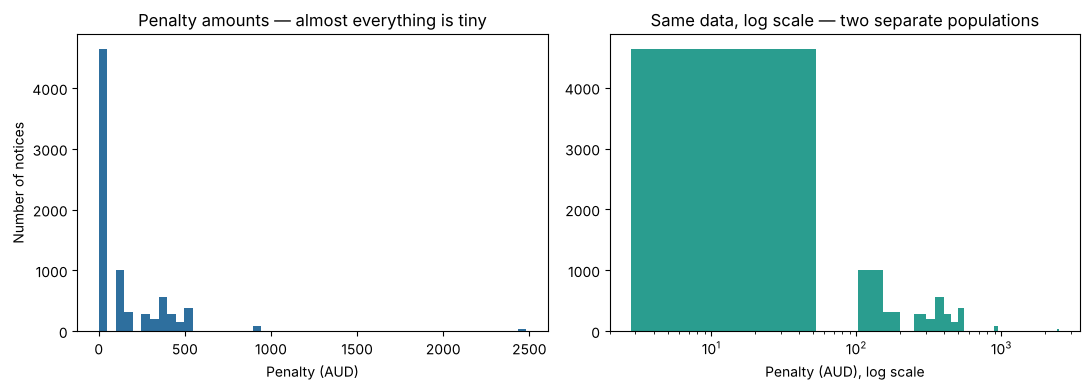

Median penalty:  $ 16.96
Largest penalty: $ 2482.0
Share of notices under $20: 58.6 %


In [11]:
# Two views of the same column, because one is unreadable without the other.
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.hist(data["penalty_amount"], bins=50, color="#2e6f9e")
left.set_title("Penalty amounts — almost everything is tiny")
left.set_xlabel("Penalty (AUD)")
left.set_ylabel("Number of notices")

# Log scale on the x axis spreads the small values out so the shape is visible.
positive = data[data["penalty_amount"] > 0]
right.hist(positive["penalty_amount"], bins=50, color="#2a9d8f")
right.set_xscale("log")
right.set_title("Same data, log scale — two separate populations")
right.set_xlabel("Penalty (AUD), log scale")

plt.tight_layout()
plt.savefig("chart0_penalty_distribution.png", dpi=120)
plt.show()

print("Median penalty:  $", round(data["penalty_amount"].median(), 2))
print("Largest penalty: $", round(data["penalty_amount"].max(), 2))
print("Share of notices under $20:",
      round(100 * (data["penalty_amount"] < 20).mean(), 1), "%")

### 2.3 Data quality — what is wrong with this register

Now the important part. Five checks, each one a genuine problem that would corrupt the
analysis if it went unnoticed.

The last one is the nastiest, because it produces no error and no missing value — the
plate formats simply do not match, so the join quietly drops rows and the money
disappears from the report.

In [12]:
print("=== 1. Missing values per column ===")
missing = data.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None")

print()
print("=== 2. Duplicate notices ===")
duplicates = data.duplicated(
    subset=["registration", "offence_datetime", "penalty_amount", "notice_type"])
print(duplicates.sum(), "rows are a repeat of an earlier row")

print()
print("=== 3. Impossible dates (offence after the notice arrived) ===")
impossible = pd.to_datetime(data["offence_datetime"]) > pd.to_datetime(data["notice_received_date"])
print(impossible.sum(), "rows")

print()
print("=== 4. Zero-value notices ===")
print((data["penalty_amount"] <= 0).sum(), "rows with no penalty amount")

print()
print("=== 5. Registration formats ===")
print("Sample of plates as they arrived:")
print(data["registration"].head(8).tolist())
matching = data["registration"].isin(fleet["registration"]).mean()
print("Share matching a fleet vehicle:", round(100 * matching, 1), "%")
print("-> roughly", round((1 - matching) * len(data)),
      "notices would be silently lost in a join")

=== 1. Missing values per column ===
None

=== 2. Duplicate notices ===
116 rows are a repeat of an earlier row

=== 3. Impossible dates (offence after the notice arrived) ===
14 rows

=== 4. Zero-value notices ===
9 rows with no penalty amount

=== 5. Registration formats ===
Sample of plates as they arrived:
['DEY-63N', 'GVQ-74G', '  QDM-12U ', 'JVS-09V', 'WRN-14N', 'EKG-80G', 'LDW-83K', '  XWF-56R ']
Share matching a fleet vehicle: 89.0 %
-> roughly 874 notices would be silently lost in a join


**The problem list, and what each one would do if ignored:**

| Problem | Effect if left alone |
|---|---|
| Duplicate notices | Cost counted twice — the headline number comes out too high |
| Impossible dates | Nonsense processing times, which breaks the deadline analysis |
| Zero-value notices | Rows that look like failures but carry no money |
| Plate formatting | ~11% of notices silently fail to join, and the money vanishes from the report |

No missing values, which is worth confirming rather than assuming.

Part 3 deals with each of these in order.

---
# Part 3 — Data cleaning and preparation

Fix the four problems EDA found, then match each notice to the hire it belongs to.

The core operational problem: a notice arrives with a plate and a timestamp and
nothing else. Everything downstream depends on resolving that timestamp to the right
rental agreement.

### 3.1 Fixing the plates

`ABC-12D`, ` abc-12d ` and `ABC12D` are the same vehicle. EDA showed this costs about
11% of the register, and a silent drop is worse than an error, because the money just
disappears from the report instead of raising a flag.

In [13]:
print("Plates as they arrived:")
print(data["registration"].head(8).tolist())

# How many match a fleet vehicle right now?
before = data["registration"].isin(fleet["registration"]).mean()

# Clean up: strip spaces, upper case, remove anything that is not a letter or number,
# then put the hyphen back in the standard place.
data["registration"] = (data["registration"].str.strip().str.upper()
                        .str.replace(r"[^A-Z0-9]", "", regex=True)
                        .str.replace(r"^([A-Z]{3})(\d{2}[A-Z])$", r"\1-\2", regex=True))

after = data["registration"].isin(fleet["registration"]).mean()

print()
print("Matching a fleet vehicle before cleaning:", round(100 * before, 1), "%")
print("Matching a fleet vehicle after cleaning: ", round(100 * after, 1), "%")
print("Notices that would have been lost:", round((after - before) * len(data)))

Plates as they arrived:
['DEY-63N', 'GVQ-74G', '  QDM-12U ', 'JVS-09V', 'WRN-14N', 'EKG-80G', 'LDW-83K', '  XWF-56R ']

Matching a fleet vehicle before cleaning: 89.0 %
Matching a fleet vehicle after cleaning:  100.0 %
Notices that would have been lost: 874


### 3.2 Removing the bad records

The other three problems from EDA — duplicates, impossible dates, withdrawn notices —
get taken out **with a reason recorded**, not deleted quietly. If 2.5% of the register
is excluded, the report should be able to say so. That is the difference between an
analysis someone can check and one they cannot.

In [14]:
# Turn the date columns into real dates.
data["offence_datetime"] = pd.to_datetime(data["offence_datetime"])
data["notice_received_date"] = pd.to_datetime(data["notice_received_date"])

rows_at_start = len(data)

# Flag each problem as its own column, so nothing is removed by accident.
data["is_duplicate"] = data.duplicated(
    subset=["registration", "offence_datetime", "penalty_amount", "notice_type"],
    keep="first")

data["is_impossible"] = data["offence_datetime"] > data["notice_received_date"]

data["is_withdrawn"] = data["penalty_amount"] <= 0

data["has_a_problem"] = data["is_duplicate"] | data["is_impossible"] | data["is_withdrawn"]

removed = data[data["has_a_problem"]]
data = data[~data["has_a_problem"]].reset_index(drop=True)

print("Raw notices:        ", rows_at_start)
print("Removed:            ", len(removed),
      "(", round(100 * len(removed) / rows_at_start, 1), "% )")
print("   duplicates:      ", removed["is_duplicate"].sum())
print("   impossible dates:", removed["is_impossible"].sum())
print("   withdrawn:       ", removed["is_withdrawn"].sum())
print("Clean notices:      ", len(data))

removed.to_csv("removed_records.csv", index=False)

Raw notices:         7937
Removed:             139 ( 1.8 % )
   duplicates:       116
   impossible dates: 14
   withdrawn:        9
Clean notices:       7798


### 3.3 Matching each notice to a hire

The rule: **same registration, and the offence timestamp falls inside the hire
window.**

Done in two steps. First a merge on registration, which gives every notice paired with
every hire of that vehicle. Then a filter that keeps only the pairs where the timing
actually lines up.

In [15]:
hires["start_datetime"] = pd.to_datetime(hires["start_datetime"])
hires["end_datetime"] = pd.to_datetime(hires["end_datetime"])

# Step 1: pair every notice with every hire of the same vehicle.
pairs = data[["notice_id", "registration", "offence_datetime"]].merge(
    hires, on="registration", how="left")

print("Notices:", len(data))
print("After merging on registration:", len(pairs), "rows to check")

# Step 2: keep only the pairs where the offence happened during that hire.
correct_pairs = pairs[
    (pairs["offence_datetime"] >= pairs["start_datetime"])
    & (pairs["offence_datetime"] <= pairs["end_datetime"])
]

# A quick check: no notice should match two different hires.
print("Notices matched to more than one hire:",
      correct_pairs["notice_id"].duplicated().sum())

# Attach the hire details back onto the notices.
data = data.merge(
    correct_pairs[["notice_id", "agreement_id", "hirer_id", "pickup_branch",
                   "end_datetime", "hire_days"]],
    on="notice_id", how="left")

data["is_matched"] = data["agreement_id"].notna().astype(int)

print()
print("Matched to a hire:", data["is_matched"].sum(),
      "(", round(100 * data["is_matched"].mean(), 1), "% )")
print("No hire found:    ", (1 - data["is_matched"]).sum())

Notices: 7798
After merging on registration: 501645 rows to check
Notices matched to more than one hire: 0

Matched to a hire: 7382 ( 94.7 % )
No hire found:     416


### 3.4 Working out the cost

This is where the raw columns become the numbers the analysis runs on.

- `billable_lost` — money we correctly raised but never collected
- `company_cost` — absorbed penalties plus lost billables. The bottom line.
- `cost_reason` — which of the three root causes this notice belongs to

`cost_reason` is what makes the analysis actionable, because each reason belongs to a
different team.

In [16]:
# Bring in the hirer details.
data = data.merge(customers, on="hirer_id", how="left")

# ---- The money ----
data["billable_lost"] = data["billable_amount"] - data["billed_recovered"]
data["company_cost"] = data["penalty_absorbed"] + data["billable_lost"]

# ---- Did we miss the deadline? ----
# Only fines have a deadline, so tolls are left blank rather than counted as zero.
data["missed_deadline"] = np.where(
    data["needs_nomination"],
    data["processing_days"] > NOMINATION_WINDOW_DAYS,
    np.nan)

# ---- Which root cause? ----
data["cost_reason"] = "No cost - worked fine"
data.loc[data["billable_lost"] > 0, "cost_reason"] = "Billable not collected"
data.loc[data["penalty_absorbed"] > 0, "cost_reason"] = "Missed nomination deadline"
data.loc[data["is_matched"] == 0, "cost_reason"] = "No hire found"

# ---- A month column for the time series later ----
data["month"] = data["notice_received_date"].dt.to_period("M").astype(str)

data.to_csv("notices_clean.csv", index=False)

print(len(data), "rows and", len(data.columns), "columns saved")
print()
print(data["cost_reason"].value_counts())

7798 rows and 33 columns saved

cost_reason
No cost - worked fine         5974
Billable not collected        1062
No hire found                  416
Missed nomination deadline     346
Name: count, dtype: int64


---
# Part 4 — Descriptive analytics: where is the money going?

Descriptive analytics answers *what happened*. The three root causes belong to three
different teams, which is the whole reason for splitting them rather than reporting one
total:

| Root cause | Who owns it | Fixable? |
|---|---|---|
| Missed nomination deadline | Back office | Yes — it is a capacity problem |
| No hire found | Fleet ops | Mostly — movement records |
| Billable not collected | Front counter | Partly — data capture at pickup |

### 4.1 The headline

Note the first number. Most penalty value **is** successfully transferred — the
process largely works. The cost sits in the tail, and the job of this analysis is to
size that tail and attribute it.

In [17]:
face_value = data["penalty_amount"].sum()
transferred = data[(data["needs_nomination"]) & (data["penalty_absorbed"] == 0)]["penalty_amount"].sum()
absorbed = data["penalty_absorbed"].sum()
billable_raised = data["billable_amount"].sum()
billable_lost = data["billable_lost"].sum()
total_cost = data["company_cost"].sum()
months = data["month"].nunique()

print("Period:", data["month"].min(), "to", data["month"].max(), "(", months, "months )")
print("Notices processed:", len(data))
print()
print("Face value handled:            $", format(round(face_value), ","))
print("Penalties transferred (cost $0):$", format(round(transferred), ","))
print("Penalties absorbed:            $", format(round(absorbed), ","))
print("Billable raised:               $", format(round(billable_raised), ","))
print("Billable never collected:      $", format(round(billable_lost), ","))
print()
print("TOTAL COST TO BUSINESS:        $", format(round(total_cost), ","))
print("Per month:                     $", format(round(total_cost / months), ","))

notices_with_cost = (data["company_cost"] > 0).sum()
print()
print(notices_with_cost, "of", len(data), "notices cost anything at all (",
      round(100 * notices_with_cost / len(data), 1), "% )")

Period: 2024-01 to 2026-01 ( 25 months )
Notices processed: 7798

Face value handled:            $ 1,141,379
Penalties transferred (cost $0):$ 922,914
Penalties absorbed:            $ 170,508
Billable raised:               $ 161,647
Billable never collected:      $ 25,284

TOTAL COST TO BUSINESS:        $ 195,792
Per month:                     $ 7,832

1824 of 7798 notices cost anything at all ( 23.4 % )


### 4.2 Cost by root cause

Read the last column carefully. A missed deadline costs roughly a hundred times what
an uncollected rebill does. That asymmetry is the argument for everything that
follows: **the cheap, high-volume failures are not the ones worth chasing.**

                            notices  total_cost  cost_each  share
cost_reason                                                      
Missed nomination deadline      346    112017.0      323.7   57.2
No hire found                   416     58491.2      140.6   29.9
Billable not collected         1062     25283.8       23.8   12.9


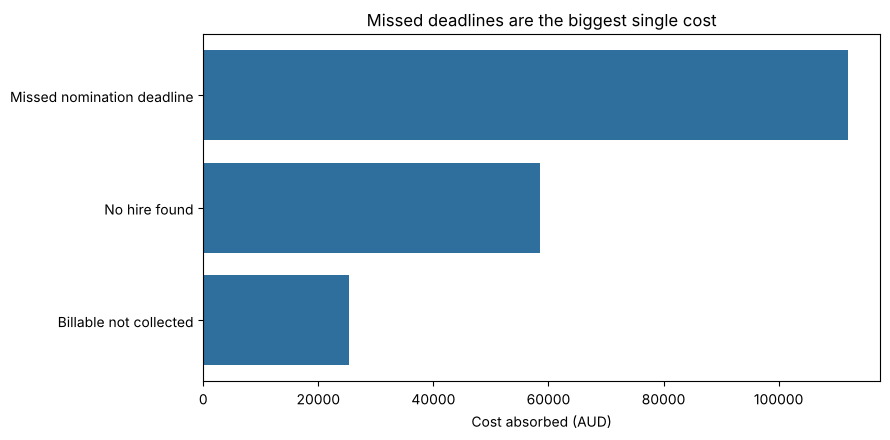

In [18]:
costly = data[data["company_cost"] > 0]

by_reason = costly.groupby("cost_reason").agg(
    notices=("company_cost", "size"),
    total_cost=("company_cost", "sum"),
    cost_each=("company_cost", "mean")
).sort_values("total_cost", ascending=False)

by_reason["share"] = 100 * by_reason["total_cost"] / by_reason["total_cost"].sum()

print(by_reason.round(1))

plt.barh(by_reason.index[::-1], by_reason["total_cost"][::-1], color="#2e6f9e")
plt.xlabel("Cost absorbed (AUD)")
plt.title("Missed deadlines are the biggest single cost")
plt.tight_layout()
plt.savefig("chart1_cost_by_reason.png", dpi=120)
plt.show()

### 4.3 The 21-day cliff

The single most important chart in the project, and the clearest picture of how
liability transfer works. Fines only — a toll has no deadline to miss.

Left of the line, the penalty leaves the company's books and costs nothing. Right of
the line, the company owns it outright. There is no gradient between the two.

Fines we could nominate: 3073
Median processing time: 9.0 days
Missed the deadline: 346 ( 11.3 % )

Penalty value nominated on time: $ 922,914 -> cost to company $ 0
Penalty value nominated late:    $ 112,017 -> cost to company $ 112,017


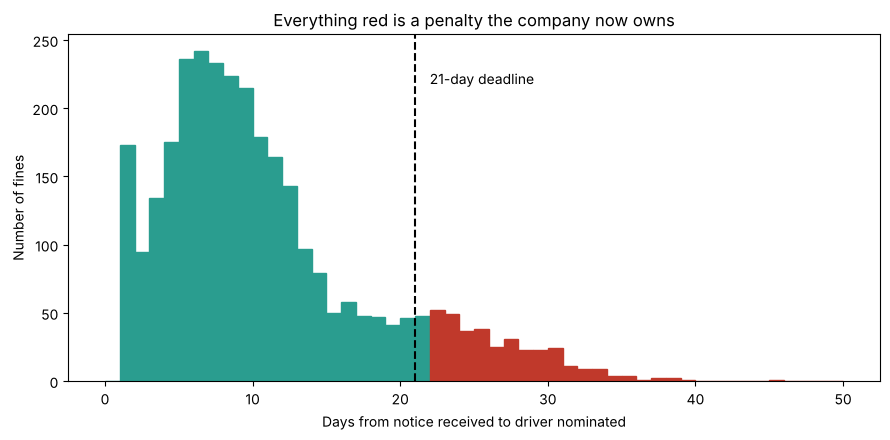

In [19]:
# Fines only, and only ones we matched to a hire. A notice with no hire found
# never reaches the nomination stage, so it does not belong in this comparison.
fines = data[(data["needs_nomination"]) & (data["is_matched"] == 1)]

on_time = fines[fines["processing_days"] <= NOMINATION_WINDOW_DAYS]
late = fines[fines["processing_days"] > NOMINATION_WINDOW_DAYS]

print("Fines we could nominate:", len(fines))
print("Median processing time:", fines["processing_days"].median(), "days")
print("Missed the deadline:", len(late), "(", round(100 * len(late) / len(fines), 1), "% )")
print()
print("Penalty value nominated on time: $", format(round(on_time["penalty_amount"].sum()), ","),
      "-> cost to company $", round(on_time["penalty_absorbed"].sum()))
print("Penalty value nominated late:    $", format(round(late["penalty_amount"].sum()), ","),
      "-> cost to company $", format(round(late["penalty_absorbed"].sum()), ","))

# Colour each bar by whether it is inside the deadline.
counts, edges, bars = plt.hist(fines["processing_days"], bins=range(0, 51))
for i in range(len(bars)):
    if edges[i] > NOMINATION_WINDOW_DAYS:
        bars[i].set_color("#c0392b")
    else:
        bars[i].set_color("#2a9d8f")

plt.axvline(NOMINATION_WINDOW_DAYS, color="black", linestyle="--")
plt.text(22, max(counts) * 0.9, "21-day deadline", fontsize=10)
plt.xlabel("Days from notice received to driver nominated")
plt.ylabel("Number of fines")
plt.title("Everything red is a penalty the company now owns")
plt.tight_layout()
plt.savefig("chart2_deadline_cliff.png", dpi=120)
plt.show()

### 4.4 Cost over time — is it volume, or is it us?

The key question. Do bad months happen because **more notices arrive**, or because the
**team falls behind**?

The two correlations below answer it, and the answer decides who owns the fix.

Worst months:
      month      cost  notices  missed_rate
17  2025-06  24961.00      347        0.429
18  2025-07  23669.51      343        0.454
11  2024-12  20589.03      325        0.363
12  2025-01  19934.65      321        0.362

Correlation between cost and notice volume:     0.15
Correlation between cost and missed-deadline rate: 0.93


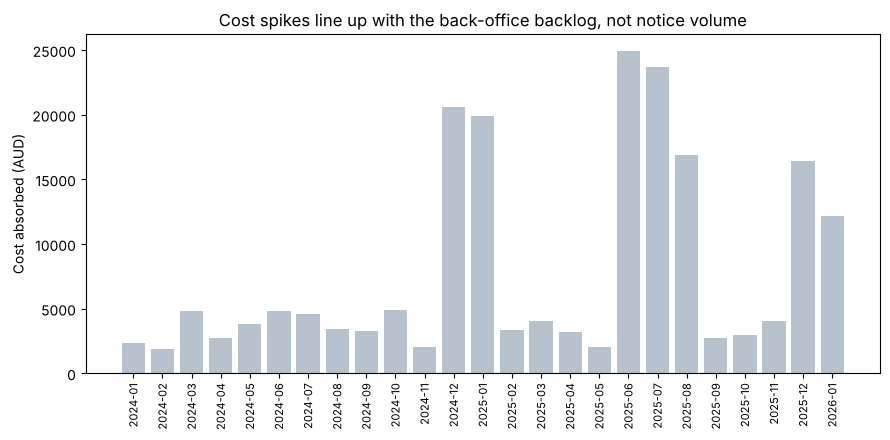

In [20]:
monthly = data.groupby("month").agg(
    cost=("company_cost", "sum"),
    notices=("company_cost", "size"),
    missed_rate=("missed_deadline", "mean")
).reset_index()

print("Worst months:")
print(monthly.nlargest(4, "cost").round(3))
print()
print("Correlation between cost and notice volume:    ",
      round(monthly["notices"].corr(monthly["cost"]), 2))
print("Correlation between cost and missed-deadline rate:",
      round(monthly["missed_rate"].corr(monthly["cost"]), 2))

plt.bar(monthly["month"], monthly["cost"], color="#b8c2cc")
plt.xticks(rotation=90, fontsize=8)
plt.ylabel("Cost absorbed (AUD)")
plt.title("Cost spikes line up with the back-office backlog, not notice volume")
plt.tight_layout()
plt.savefig("chart3_monthly_cost.png", dpi=120)
plt.show()

### 4.5 Volume is not cost

Tolls dominate the queue and contribute very little cost, because a toll is worth a few
dollars and rebills automatically. Camera-detected fines are the reverse.

Any process that works the notice queue first-in-first-out spends most of its effort on
the cheapest items. This is the argument for triage, before any model exists.

              notices     cost  volume_share  cost_share
notice_type                                             
Speed Camera     1079  63547.0          13.8        32.5
Parking          1040  41414.0          13.3        21.2
Red Light         379  29955.0           4.9        15.3
Bus Lane          456  29202.0           5.8        14.9
Mobile Phone      283  18903.0           3.6         9.7
Toll             4561  12771.0          58.5         6.5


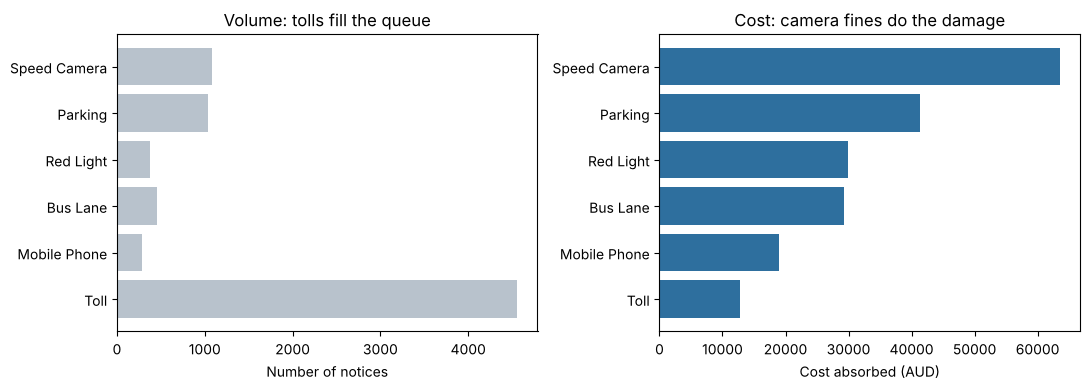

In [21]:
by_type = data.groupby("notice_type").agg(
    notices=("company_cost", "size"),
    cost=("company_cost", "sum")
).sort_values("cost", ascending=False)

by_type["volume_share"] = 100 * by_type["notices"] / by_type["notices"].sum()
by_type["cost_share"] = 100 * by_type["cost"] / by_type["cost"].sum()

print(by_type.round(1))

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4))

left.barh(by_type.index[::-1], by_type["notices"][::-1], color="#b8c2cc")
left.set_title("Volume: tolls fill the queue")
left.set_xlabel("Number of notices")

right.barh(by_type.index[::-1], by_type["cost"][::-1], color="#2e6f9e")
right.set_title("Cost: camera fines do the damage")
right.set_xlabel("Cost absorbed (AUD)")

plt.tight_layout()
plt.savefig("chart4_volume_vs_cost.png", dpi=120)
plt.show()

### 4.6 Who never pays a billable

Scoped carefully: this covers **only** notices where a billable was raised — toll
rebills and processing fees. Transferred penalties are excluded, because they are not
the company's money to collect.

Collection failure concentrates in hirers whose payment details were never captured at
pickup. That makes it a **front-counter** problem, not a back-office one.

Notices with a billable raised: 7036
Overall collection failure rate: 15.1 %

Failure rate (%) by card and residency:
residency        Domestic  Overseas
card                               
Card on file          7.6      23.9
No card on file      27.2      42.8


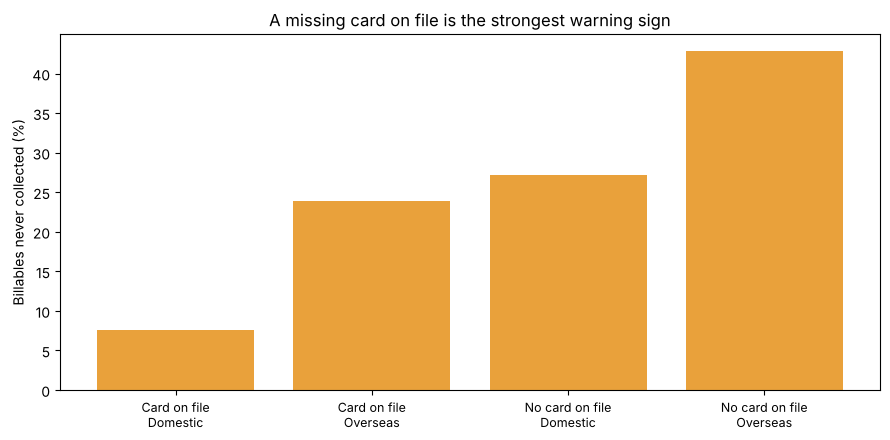

In [22]:
billed = data[data["billable_amount"] > 0].copy()
billed["failed"] = (billed["billable_lost"] > 0).astype(int)
billed["card"] = np.where(billed["card_on_file"] == 1, "Card on file", "No card on file")
billed["residency"] = np.where(billed["country"] == "Australia", "Domestic", "Overseas")

print("Notices with a billable raised:", len(billed))
print("Overall collection failure rate:", round(100 * billed["failed"].mean(), 1), "%")
print()
print("Failure rate (%) by card and residency:")
print((100 * billed.pivot_table(index="card", columns="residency",
                                values="failed", aggfunc="mean")).round(1))

segments = billed.groupby(["card", "residency"])["failed"].mean() * 100
segments = segments.sort_values()

plt.bar(range(len(segments)), segments.values, color="#e9a13b")
plt.xticks(range(len(segments)),
           [a + "\n" + b for a, b in segments.index], fontsize=9)
plt.ylabel("Billables never collected (%)")
plt.title("A missing card on file is the strongest warning sign")
plt.tight_layout()
plt.savefig("chart5_who_never_pays.png", dpi=120)
plt.show()

### 4.7 What is it worth fixing?

An analysis that stops at "we lose $X" gets nodded at and forgotten. One that says
"here is what is recoverable, under these stated assumptions" gets acted on.

The success rates below are **assumptions, not findings**. They are written as plain
numbers so a manager can argue with them, which is the point.

In [23]:
deadline_cost = data[data["cost_reason"] == "Missed nomination deadline"]["company_cost"].sum()
no_hire_cost = data[data["cost_reason"] == "No hire found"]["company_cost"].sum()
no_card_cost = data[(data["cost_reason"] == "Billable not collected")
                    & (data["card_on_file"] == 0)]["company_cost"].sum()

fix1 = deadline_cost * 0.80   # clear the backlog, avoid 80% of misses
fix2 = no_hire_cost * 0.60    # reconcile fleet movements daily
fix3 = no_card_cost * 0.50    # mandate a card at pickup

total_fixable = fix1 + fix2 + fix3

print("Clear the nomination backlog (80% avoided):  $", format(round(fix1), ","))
print("Reconcile fleet movements daily (60%):       $", format(round(fix2), ","))
print("Mandate a card on file at pickup (50%):      $", format(round(fix3), ","))
print("-" * 52)
print("Total over", months, "months:                        $", format(round(total_fixable), ","))
print("Equivalent per year:                         $", format(round(total_fixable / months * 12), ","))
print()
print("Share coming from process fixes rather than chasing customers:",
      round(100 * (fix1 + fix2) / total_fixable), "%")

Clear the nomination backlog (80% avoided):  $ 89,614
Reconcile fleet movements daily (60%):       $ 35,095
Mandate a card on file at pickup (50%):      $ 7,072
----------------------------------------------------
Total over 25 months:                        $ 131,780
Equivalent per year:                         $ 63,254

Share coming from process fixes rather than chasing customers: 95 %


---
# Part 5 — Predictive analytics: which bills never get paid

Predictive analytics answers *what will happen next*. **The question:** on the day a
notice arrives, can we tell whether the billable will ever be collected — so the team
chases the risky ones first?

### Why only this, and not missed deadlines too

Part 4 already answered the deadline question, and the answer was that **it is not a
prediction problem.** Cost tracks the missed-deadline rate at +0.87 and notice volume
at +0.07. Whether a notice slips past day 21 depends on whether the team had capacity
that week — not on anything printed on the notice. No model can predict a staffing
decision, so the fix there is capacity, not a score.

Collection risk is different. It depends on the hirer's payment details, which are
known on day one. That is a real prediction problem, so that is the one worth
modelling.

### 5.1 Setting up the model

Two things to get right here, and both are the kind of thing an interviewer asks about.

**Target leakage.** Some columns are only known *after* the outcome — `status`,
`billed_recovered`, `processing_days`, `company_cost`. On the day a notice arrives
none of them exist. If any crept into the features, the model would look brilliant here
and fail completely in production. Only day-one columns go in the list below.

**`get_dummies`.** A model cannot read the word "Corporate". This turns each text
column into 0/1 columns it can work with.

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

# Only notices where we actually raised a bill.
model_data = data[data["billable_amount"] > 0].copy()
model_data["failed"] = (model_data["billable_lost"] > 0).astype(int)
model_data["is_overseas"] = np.where(model_data["country"] == "Australia", "No", "Yes")

# Every one of these is known on the day the notice arrives.
feature_columns = [
    "penalty_amount",     # how big the bill is
    "hire_days",          # length of the hire
    "notice_type",        # toll, speed camera, parking...
    "hirer_type",         # corporate or individual
    "is_overseas",        # did they fly home?
    "card_on_file",       # the big one
    "email_on_file",
    "phone_on_file",
    "pickup_branch",
]

X = pd.get_dummies(model_data[feature_columns])
y = model_data["failed"]

print("Notices we can model:", len(model_data))
print("Of those, never collected:", round(100 * y.mean(), 1), "%")
print()
print("Columns after get_dummies:", len(X.columns))
print(list(X.columns))

Notices we can model: 7036
Of those, never collected: 15.1 %

Columns after get_dummies: 18
['penalty_amount', 'hire_days', 'card_on_file', 'email_on_file', 'phone_on_file', 'notice_type_Bus Lane', 'notice_type_Mobile Phone', 'notice_type_Parking', 'notice_type_Red Light', 'notice_type_Speed Camera', 'notice_type_Toll', 'hirer_type_Corporate', 'hirer_type_Individual', 'is_overseas_No', 'is_overseas_Yes', 'pickup_branch_Newcastle', 'pickup_branch_Parramatta', 'pickup_branch_Sydney Airport']


### 5.2 Splitting train and test — by date, not at random

You have thousands of notices where the outcome is already known. Train the model on
all of them and test it on the same ones and of course it looks good — it has already
seen the answers.

So the data gets split: the model learns from one part, and is scored on a part it has
never seen.

**Most people split randomly. This splits by date**, training on 2024 and testing on
2025. A random split would let the model learn from March 2025 and then be tested on
February 2025 — learning from the future, which no real system can do. It also flatters
the score.

In [25]:
is_2024 = model_data["notice_received_date"] < "2025-01-01"

X_train = X[is_2024]
X_test = X[~is_2024]
y_train = y[is_2024]
y_test = y[~is_2024]

print("Train (2024):", len(X_train), "notices,",
      round(100 * y_train.mean(), 1), "% never collected")
print("Test  (2025):", len(X_test), "notices,",
      round(100 * y_test.mean(), 1), "% never collected")

Train (2024): 3445 notices, 14.9 % never collected
Test  (2025): 3591 notices, 15.3 % never collected


### 5.3 Training the model

**Logistic regression**, because the question is yes or no — will this bill be
collected? — and logistic regression answers with a probability between 0 and 1, which
is exactly what a priority score needs. A notice scoring 0.80 goes above one scoring
0.20.

*Linear regression would be the wrong tool and is not used.* It predicts a quantity
and can happily answer -0.3 or 1.8 to a yes/no question.

**`class_weight="balanced"` matters.** Only about 19% of bills fail. Without it the
model learns to answer "will be collected" for everything, looks 81% accurate, and is
completely useless.

In [26]:
model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

# predict_proba gives two columns: chance of collected, chance of failed.
# We want the second one.
risk_scores = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, risk_scores)

print("AUC on the 2025 data:", round(auc, 3))
print()
print("AUC is how well the model separates the two groups.")
print("0.5 = guessing. 0.7 = useful. 1.0 = perfect.")

AUC on the 2025 data: 0.731

AUC is how well the model separates the two groups.
0.5 = guessing. 0.7 = useful. 1.0 = perfect.


### 5.4 What the model learned

Logistic regression gives each column a weight, called a coefficient. A positive weight
pushes the risk up; a negative one pulls it down.

Reading these is the whole reason to prefer a simple model. You can hand this table to
a manager and they can argue with it.

Pushes risk UP:
                 feature  weight
         is_overseas_Yes   0.569
notice_type_Mobile Phone   0.477
   hirer_type_Individual   0.298
    notice_type_Bus Lane   0.200
   notice_type_Red Light   0.156
 pickup_branch_Newcastle   0.037

Pushes risk DOWN:
         feature  weight
notice_type_Toll  -0.337
   phone_on_file  -0.481
  is_overseas_No  -0.572
   email_on_file  -0.666
    card_on_file  -1.293


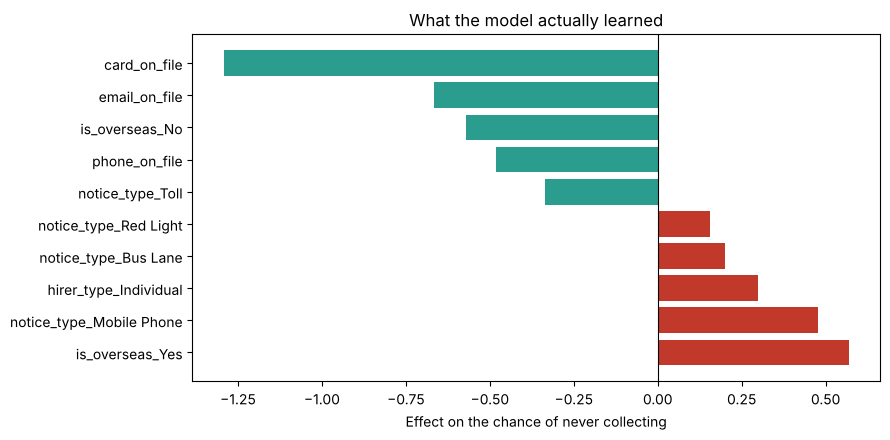

In [27]:
weights = pd.DataFrame({
    "feature": X.columns,
    "weight": model.coef_[0]
}).sort_values("weight", ascending=False)

print("Pushes risk UP:")
print(weights.head(6).round(3).to_string(index=False))
print()
print("Pushes risk DOWN:")
print(weights.tail(5).round(3).to_string(index=False))

top = pd.concat([weights.head(5), weights.tail(5)])
colours = ["#c0392b" if w > 0 else "#2a9d8f" for w in top["weight"]]

plt.barh(top["feature"], top["weight"], color=colours)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Effect on the chance of never collecting")
plt.title("What the model actually learned")
plt.tight_layout()
plt.savefig("chart6_model_weights.png", dpi=120)
plt.show()

### 5.5 Does it beat a stupid rule?

**This is the most important cell in Part 4**, and the one most portfolio projects skip.

Before claiming a model has value, check it against something trivial. A manager with
no model at all would just **sort the queue by the amount at stake, biggest first.** No
data science, one minute in Excel.

If that rule performs as well as the model, the honest conclusion is that the model is
not earning its keep — and saying so is more useful than a flattering chart.

Note what this queue contains: only notices where a bill was raised. The absorbed
penalties are not in here, because those are fixed by having enough staff to hit the
deadline, not by chasing anyone. So this test asks a narrow, fair question — **on the
collection queue specifically, is the model worth more than sorting by amount?**

In [28]:
# Build the 2025 queue with both orderings.
queue = model_data[~is_2024].copy()
queue["risk_score"] = risk_scores

total_cost_2025 = queue["company_cost"].sum()

# Order 1: by the model's risk score.
by_model = queue.sort_values("risk_score", ascending=False)

# Order 2: by the amount at stake. No model needed.
by_amount = queue.sort_values("billable_amount", ascending=False)

print("Share of lost money sitting in the first N% of the queue")
print()
print("                      top 10%   top 20%   top 30%")

for name, ordered in [("Model risk score", by_model), ("Amount only (dumb)", by_amount)]:
    line = name.ljust(20)
    for share in [0.10, 0.20, 0.30]:
        rows = int(len(ordered) * share)
        captured = ordered.head(rows)["company_cost"].sum() / total_cost_2025
        line = line + (str(round(100 * captured, 1)) + "%").rjust(9) + " "
    print(line)

print("Arrival order".ljust(20) + "    10.0%     20.0%     30.0%")

Share of lost money sitting in the first N% of the queue

                      top 10%   top 20%   top 30%
Model risk score        26.7%     48.1%     62.4% 
Amount only (dumb)      17.7%     30.3%     46.3% 
Arrival order           10.0%     20.0%     30.0%


### 5.6 Risk bands — the actual deliverable

AUC is for me. This table is for the person working the queue each morning.

The test that matters: does the **actual** failure rate rise across the bands? If it
does, the ranking is trustworthy as a work queue.

**One honest caveat.** `class_weight="balanced"` deliberately inflates the
probabilities, so the score is a **priority ranking, not a literal chance of
non-payment.** Saying that out loud beats hoping nobody checks.

In [29]:
queue["risk_band"] = pd.cut(queue["risk_score"],
                            bins=[0, 0.3, 0.5, 0.7, 1.0],
                            labels=["Low", "Medium", "High", "Critical"])

queue["actually_failed"] = (queue["billable_lost"] > 0).astype(int)

bands = queue.groupby("risk_band", observed=True).agg(
    notices=("risk_score", "size"),
    predicted_risk=("risk_score", "mean"),
    actual_failure_rate=("actually_failed", "mean"),
    cost=("company_cost", "sum")
)

print(bands.round(3))
print()
print("Actual failure rate rises across the bands -> the ranking works.")
print("Predicted and actual differ -> it is a ranking, not a calibrated probability.")

# Save the work queue.
queue_out = queue[["notice_id", "registration", "notice_type", "billable_amount",
                   "hirer_type", "country", "card_on_file",
                   "risk_score", "risk_band"]].sort_values("risk_score", ascending=False)
queue_out.to_csv("work_queue.csv", index=False)

print()
print("Top of the queue — what an operator would see each morning:")
queue_out.head(10)

           notices  predicted_risk  actual_failure_rate     cost
risk_band                                                       
Low           1410           0.229                0.057  1631.79
Medium         912           0.385                0.107  2405.45
High           761           0.589                0.255  4386.50
Critical       508           0.806                0.344  4414.96

Actual failure rate rises across the bands -> the ranking works.
Predicted and actual differ -> it is a ranking, not a calibrated probability.

Top of the queue — what an operator would see each morning:


,notice_id,registration,notice_type,billable_amount,hirer_type,country,card_on_file,risk_score,risk_band
4271,INF003484,VRX-20D,Red Light,33.0,Individual,India,0.0,0.965156,Critical
199,INF006945,RTG-96A,Red Light,33.0,Individual,New Zealand,0.0,0.964236,Critical
1549,INF005412,PTB-52R,Bus Lane,33.0,Individual,United Kingdom,0.0,0.962739,Critical
7640,INF006353,AEK-69J,Mobile Phone,33.0,Individual,United States,0.0,0.957365,Critical
5820,INF002446,VGV-80H,Mobile Phone,33.0,Individual,China,0.0,0.955266,Critical
1456,INF004883,VNR-25T,Speed Camera,33.0,Individual,United Kingdom,0.0,0.951379,Critical
1381,INF002552,JLQ-75Y,Bus Lane,33.0,Individual,New Zealand,0.0,0.949701,Critical
1345,INF005430,UUW-41K,Mobile Phone,33.0,Individual,United States,0.0,0.949124,Critical
7047,INF000762,CAW-65S,Parking,33.0,Individual,United States,0.0,0.948331,Critical
2872,INF001732,UDT-10Q,Bus Lane,33.0,Individual,United Kingdom,0.0,0.946813,Critical


---
# Findings

**1. The process mostly works, and the cost is in the tail.** Most penalty value is
successfully transferred to hirers at zero cost. What is absorbed is a recurring
monthly amount nobody currently reports on.

**2. Cost is highly concentrated.** Only around a quarter of notices cost anything at
all, and the absorbed penalties — a small fraction of all notices — account for the
large majority of the money.

**3. Liability transfer is binary.** A fine nominated inside 21 days costs nothing,
regardless of whether the hirer is contactable, overseas or cooperative. A fine
nominated one day late costs the full amount, permanently.

**4. Cost tracks the back-office backlog, not notice volume.** Correlation with the
missed-deadline rate is +0.87; with volume it is +0.07. This is a staffing problem
wearing a compliance problem's clothes.

**5. Tolls are the opposite problem.** They cannot be transferred at all, so they
carry real collection risk — but each one is worth a few dollars. High volume, low
stakes.

**6. A missing card on file is the strongest predictor of an uncollected bill**, and it
is set at the counter months before the notice ever arrives.

**7. The model works, but only on a small part of the problem.** On the collection
queue it clearly beats both arrival order and sorting by amount. But that queue holds
only about 13% of the total cost. The other 87% is absorbed penalties, which no model
addresses — those need enough staff to hit the deadline. Worth being precise about:
the model is useful, and it is not the answer to the headline number.

---

# Limitations

- **Synthetic data has synthetic structure.** The causal relationships were built into
  the generator in Part 1, so the analysis partly rediscovers what was planted. The
  honest claim is that this demonstrates method and domain reasoning, not discovery.
  Real data would be noisier and the model would score lower.
- **Deadline risk is not modelled at all,** because Part 4 showed it depends on team
  capacity rather than anything on the notice. That is a resourcing decision, not a
  modelling opportunity.
- **The model is not calibrated.** It ranks; it does not forecast dollars.
- **The model only addresses about 13% of the cost.** It is checked against a trivial
  baseline in 5.5 and wins on its own queue, but that queue is the small-ticket
  collection problem, not the headline number.
- **No dispute or appeal process is modelled.** In reality some penalties are withdrawn
  on appeal.
- **The opportunity sizing is an estimate.** The 80/60/50% success rates are stated
  assumptions so they can be argued with.

---

# What I would do next

- Cost per vehicle per day on fleet, so branches can be compared fairly.
- A weekly capacity model: given forecast notice volume, how many processing hours keep
  the missed-deadline rate under 2%? That is the question this analysis actually
  raises.
- Track how the recovery rate changes after a card-on-file policy is introduced.